# Phase 3 - Notebook 2: Extraccion de Segmentos para Modelado

Este notebook extrae los segmentos desde el dataset unificado y crea salidas listas para la siguiente etapa (autoencoder/embeddings).

Incluye:
1. Carga de segmentos unificados y serie H1 de precio
2. Extraccion real de cada trozo por `start_ts/end_ts`
3. Export de catalogo + dataset long-format
4. Construccion de secuencias de largo fijo (normalizadas)
5. Split temporal train/val/test


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 280)


In [2]:
# =========================
# Config
# =========================
SEGMENTS_PATH = Path('./phases/phase02_market_alphabet/output_segments_unificados/USDJPY_segments_todos_unificados.parquet')
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet')

OUTPUT_DIR = Path('./phases/phase03_segment_analysis/output_extraccion')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CATALOG_PARQUET = OUTPUT_DIR / 'USDJPY_segments_extracted_catalog.parquet'
CATALOG_CSV = OUTPUT_DIR / 'USDJPY_segments_extracted_catalog.csv'
LONG_PARQUET = OUTPUT_DIR / 'USDJPY_segments_extracted_long.parquet'
LONG_CSV = OUTPUT_DIR / 'USDJPY_segments_extracted_long.csv'
SPLIT_PARQUET = OUTPUT_DIR / 'USDJPY_segments_split_temporal.parquet'
SPLIT_CSV = OUTPUT_DIR / 'USDJPY_segments_split_temporal.csv'
NPZ_PATH = OUTPUT_DIR / 'USDJPY_segments_sequences_fixedlen.npz'

# Filtros de extraccion
MIN_BARS_EXTRACTED = 6
MAX_BARS_EXTRACTED = 256

# Secuencias fijas para modelos
TARGET_LEN = 128
N_SHOW_EXAMPLES = 9

# Split temporal por cuantiles sobre start_ts
TRAIN_Q = 0.70
VAL_Q = 0.85

print('SEGMENTS_PATH =', SEGMENTS_PATH)
print('PRICE_PATH =', PRICE_PATH)
print('OUTPUT_DIR =', OUTPUT_DIR)


SEGMENTS_PATH = ./phases/phase02_market_alphabet/output_segments_unificados/USDJPY_segments_todos_unificados.parquet
PRICE_PATH = ./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet
OUTPUT_DIR = ./phases/phase03_segment_analysis/output_extraccion


In [3]:
# =========================
# Helpers
# =========================
def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001


def zscore_safe(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    m = np.nanmean(x)
    s = np.nanstd(x)
    if not np.isfinite(s) or s < eps:
        return np.zeros_like(x, dtype=np.float32)
    return ((x - m) / (s + eps)).astype(np.float32)


def resample_to_len(x: np.ndarray, target_len: int) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return np.zeros(target_len, dtype=np.float32)
    if len(x) == 1:
        return np.full(target_len, float(x[0]), dtype=np.float32)
    src_idx = np.linspace(0.0, 1.0, num=len(x), dtype=float)
    dst_idx = np.linspace(0.0, 1.0, num=target_len, dtype=float)
    y = np.interp(dst_idx, src_idx, x)
    return y.astype(np.float32)


def load_segments(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe {path}')
    df = pd.read_parquet(path).copy()

    for c in ['start_ts', 'end_ts', 'created_at']:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors='coerce')

    for c in ['start_idx', 'end_idx', 'n_bars']:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')

    if 'global_segment_id' not in df.columns:
        df['global_segment_id'] = [f'seg_{i:06d}' for i in range(len(df))]

    return df


def load_price(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe {path}')

    keep = ['timestamp', 'open', 'high', 'low', 'close']
    df = pd.read_parquet(path, columns=keep).copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    for c in ['open', 'high', 'low', 'close']:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df = df.dropna(subset=['timestamp', 'close'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
    return df


In [4]:
# =========================
# Carga de data base
# =========================
SEG = load_segments(SEGMENTS_PATH)
PX = load_price(PRICE_PATH)
PX_TS = PX.set_index('timestamp').sort_index()

print(f'Segmentos de entrada: {len(SEG):,}')
print('Rango segmentos:', SEG['start_ts'].min(), '->', SEG['end_ts'].max())
print(f'Precio H1 rows: {len(PX):,}')
print('Rango precio:', PX['timestamp'].min(), '->', PX['timestamp'].max())
print('Conteo por origen:')
print(SEG['segment_origin'].value_counts(dropna=False).to_string())


Segmentos de entrada: 1,024
Rango segmentos: 2015-01-01 13:00:00 -> 2019-12-22 22:00:00
Precio H1 rows: 155,465
Rango precio: 2000-05-30 17:00:00 -> 2025-12-05 16:00:00
Conteo por origen:
segment_origin
automatico    430
manual        389
ia            205


In [5]:
# =========================
# Extraccion por ventana temporal
# =========================
catalog_rows = []
long_rows = []

for _, r in SEG.iterrows():
    sid = str(r.get('global_segment_id'))
    symbol = str(r.get('symbol', 'USDJPY'))
    s = pd.to_datetime(r.get('start_ts'), errors='coerce')
    e = pd.to_datetime(r.get('end_ts'), errors='coerce')

    if pd.isna(s) or pd.isna(e) or e < s:
        continue

    # Extraemos por timestamps para evitar inconsistencias de start_idx/end_idx entre fuentes
    w = PX_TS.loc[(PX_TS.index >= s) & (PX_TS.index <= e), ['open', 'high', 'low', 'close']].copy()
    if len(w) < MIN_BARS_EXTRACTED:
        continue

    if len(w) > MAX_BARS_EXTRACTED:
        w = w.iloc[:MAX_BARS_EXTRACTED].copy()

    close_arr = w['close'].to_numpy(dtype=float)
    open_arr = w['open'].to_numpy(dtype=float)
    high_arr = w['high'].to_numpy(dtype=float)
    low_arr = w['low'].to_numpy(dtype=float)

    ps = pip_size(symbol)
    move_pips_extracted = (float(close_arr[-1]) - float(close_arr[0])) / ps
    range_pips_extracted = (float(np.nanmax(high_arr)) - float(np.nanmin(low_arr))) / ps

    row = {
        'global_segment_id': sid,
        'symbol': symbol,
        'segment_origin': r.get('segment_origin', np.nan),
        'source_name': r.get('source_name', np.nan),
        'segment_label_unified': r.get('pattern_type', r.get('label', r.get('proxy_label', np.nan))),
        'start_ts': pd.Timestamp(w.index[0]),
        'end_ts': pd.Timestamp(w.index[-1]),
        'n_bars_extracted': int(len(w)),
        'duration_hours_extracted': float(len(w)),
        'move_pips_extracted': float(move_pips_extracted),
        'abs_move_pips_extracted': float(abs(move_pips_extracted)),
        'range_pips_extracted': float(range_pips_extracted),
        'score_unified_ref': r.get('score', r.get('peak_score', np.nan)),
        'orig_n_bars': r.get('n_bars', np.nan),
        'orig_start_ts': r.get('start_ts', pd.NaT),
        'orig_end_ts': r.get('end_ts', pd.NaT),
    }
    catalog_rows.append(row)

    # Long format por barra (util para feature engineering posterior)
    ts_vals = w.index.to_numpy()
    for i in range(len(w)):
        long_rows.append({
            'global_segment_id': sid,
            'step': int(i),
            'timestamp': pd.Timestamp(ts_vals[i]),
            'open': float(open_arr[i]),
            'high': float(high_arr[i]),
            'low': float(low_arr[i]),
            'close': float(close_arr[i]),
        })

CAT = pd.DataFrame(catalog_rows)
LONG = pd.DataFrame(long_rows)

if CAT.empty:
    raise RuntimeError('No se extrajeron segmentos. Revisa timestamps y filtros.')

CAT = CAT.sort_values('start_ts').reset_index(drop=True)
LONG = LONG.sort_values(['global_segment_id', 'step']).reset_index(drop=True)

print(f'Segmentos extraidos: {len(CAT):,}')
print(f'Rows long-format: {len(LONG):,}')
print('Conteo por origen (extraidos):')
print(CAT['segment_origin'].value_counts(dropna=False).to_string())

display(CAT.head(10))


Segmentos extraidos: 991
Rows long-format: 16,347
Conteo por origen (extraidos):
segment_origin
automatico    430
manual        356
ia            205


,global_segment_id,symbol,segment_origin,source_name,segment_label_unified,start_ts,end_ts,n_bars_extracted,duration_hours_extracted,move_pips_extracted,abs_move_pips_extracted,range_pips_extracted,score_unified_ref,orig_n_bars,orig_start_ts,orig_end_ts
0,beyond_sota_000090,USDJPY,automatico,beyond_sota,NaN,2015-01-01 13:00:00,2015-01-02 09:00:00,19,19.0,95.199585,95.199585,107.599640,4.370705,19,2015-01-01 13:00:00,2015-01-02 09:00:00
1,beyond_sota_000180,USDJPY,automatico,beyond_sota,NaN,2015-01-02 10:00:00,2015-01-04 17:00:00,8,8.0,33.699799,33.699799,81.400299,2.747459,8,2015-01-02 10:00:00,2015-01-04 17:00:00
2,beyond_sota_000235,USDJPY,automatico,beyond_sota,NaN,2015-01-04 21:00:00,2015-01-05 21:00:00,25,25.0,-99.700165,99.700165,148.699951,2.137900,25,2015-01-04 21:00:00,2015-01-05 21:00:00
3,beyond_sota_000077,USDJPY,automatico,beyond_sota,NaN,2015-01-05 20:00:00,2015-01-06 01:00:00,6,6.0,-65.100098,65.100098,79.599762,4.652763,6,2015-01-05 20:00:00,2015-01-06 01:00:00
4,beyond_sota_000009,USDJPY,automatico,beyond_sota,NaN,2015-01-06 06:00:00,2015-01-06 11:00:00,6,6.0,-109.600067,109.600067,119.100189,8.680612,6,2015-01-06 06:00:00,2015-01-06 11:00:00
5,beyond_sota_000083,USDJPY,automatico,beyond_sota,NaN,2015-01-06 16:00:00,2015-01-06 21:00:00,6,6.0,68.399811,68.399811,80.400085,4.593802,6,2015-01-06 16:00:00,2015-01-06 21:00:00
6,beyond_sota_000091,USDJPY,automatico,beyond_sota,NaN,2015-01-07 04:00:00,2015-01-07 11:00:00,8,8.0,69.699860,69.699860,95.100403,4.366389,8,2015-01-07 04:00:00,2015-01-07 11:00:00
7,beyond_sota_000064,USDJPY,automatico,beyond_sota,NaN,2015-01-07 14:00:00,2015-01-08 01:00:00,12,12.0,92.499542,92.499542,105.200195,5.108593,12,2015-01-07 14:00:00,2015-01-08 01:00:00
8,beyond_sota_000256,USDJPY,automatico,beyond_sota,NaN,2015-01-08 01:00:00,2015-01-08 08:00:00,8,8.0,-41.199493,41.199493,53.900146,1.855401,8,2015-01-08 01:00:00,2015-01-08 08:00:00
9,beyond_sota_000369,USDJPY,automatico,beyond_sota,NaN,2015-01-08 11:00:00,2015-01-08 19:00:00,9,9.0,29.800415,29.800415,42.300415,0.820549,9,2015-01-08 11:00:00,2015-01-08 19:00:00


In [6]:
# =========================
# Export de extraccion base
# =========================
CAT.to_parquet(CATALOG_PARQUET, index=False)
CAT.to_csv(CATALOG_CSV, index=False)
LONG.to_parquet(LONG_PARQUET, index=False)
LONG.to_csv(LONG_CSV, index=False)

print('Guardado base:')
print(' -', CATALOG_PARQUET)
print(' -', CATALOG_CSV)
print(' -', LONG_PARQUET)
print(' -', LONG_CSV)


Guardado base:
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.csv
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.parquet
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.csv


In [7]:
# =========================
# Secuencias fijas para autoencoder
# =========================
seqs = []
ids = []
origins = []
sources = []
start_ts_vec = []

for sid, g in LONG.groupby('global_segment_id', sort=False):
    g = g.sort_values('step')
    close_arr = g['close'].to_numpy(dtype=float)

    # Normalizacion por segmento (forma geometrica)
    z = zscore_safe(close_arr)

    # Reescala a largo fijo
    z_fix = resample_to_len(z, TARGET_LEN)

    seqs.append(z_fix)
    ids.append(str(sid))

    cat_row = CAT.loc[CAT['global_segment_id'] == sid].iloc[0]
    origins.append(str(cat_row.get('segment_origin', 'na')))
    sources.append(str(cat_row.get('source_name', 'na')))
    start_ts_vec.append(pd.Timestamp(cat_row['start_ts']))

X = np.vstack(seqs).astype(np.float32)
ids = np.asarray(ids, dtype='U64')
origins = np.asarray(origins, dtype='U32')
sources = np.asarray(sources, dtype='U64')
start_ts_arr = np.asarray([str(x) for x in start_ts_vec], dtype='U32')

print('X shape =', X.shape)
print('dtype =', X.dtype)
print('mean/std global =', float(np.nanmean(X)), float(np.nanstd(X)))

np.savez_compressed(
    NPZ_PATH,
    X=X,
    global_segment_id=ids,
    segment_origin=origins,
    source_name=sources,
    start_ts=start_ts_arr,
)

print('Guardado secuencias:', NPZ_PATH)


X shape = (991, 128)
dtype = float32
mean/std global = 0.0006602105568163097 0.8817635178565979
Guardado secuencias: ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_sequences_fixedlen.npz


In [8]:
# =========================
# Split temporal train/val/test
# =========================
SPLIT = CAT[['global_segment_id', 'start_ts', 'end_ts', 'segment_origin', 'source_name', 'n_bars_extracted']].copy()
SPLIT = SPLIT.sort_values('start_ts').reset_index(drop=True)

q_train = SPLIT['start_ts'].quantile(TRAIN_Q)
q_val = SPLIT['start_ts'].quantile(VAL_Q)

SPLIT['split'] = 'test'
SPLIT.loc[SPLIT['start_ts'] <= q_train, 'split'] = 'train'
SPLIT.loc[(SPLIT['start_ts'] > q_train) & (SPLIT['start_ts'] <= q_val), 'split'] = 'val'

SPLIT.to_parquet(SPLIT_PARQUET, index=False)
SPLIT.to_csv(SPLIT_CSV, index=False)

print('q_train =', q_train)
print('q_val =', q_val)
print('split counts:')
print(SPLIT['split'].value_counts().to_string())
print('Guardado split:')
print(' -', SPLIT_PARQUET)
print(' -', SPLIT_CSV)


q_train = 2016-09-22 22:00:00
q_val = 2017-11-16 00:00:00
split counts:
split
train    695
test     149
val      147
Guardado split:
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.parquet
 - ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.csv


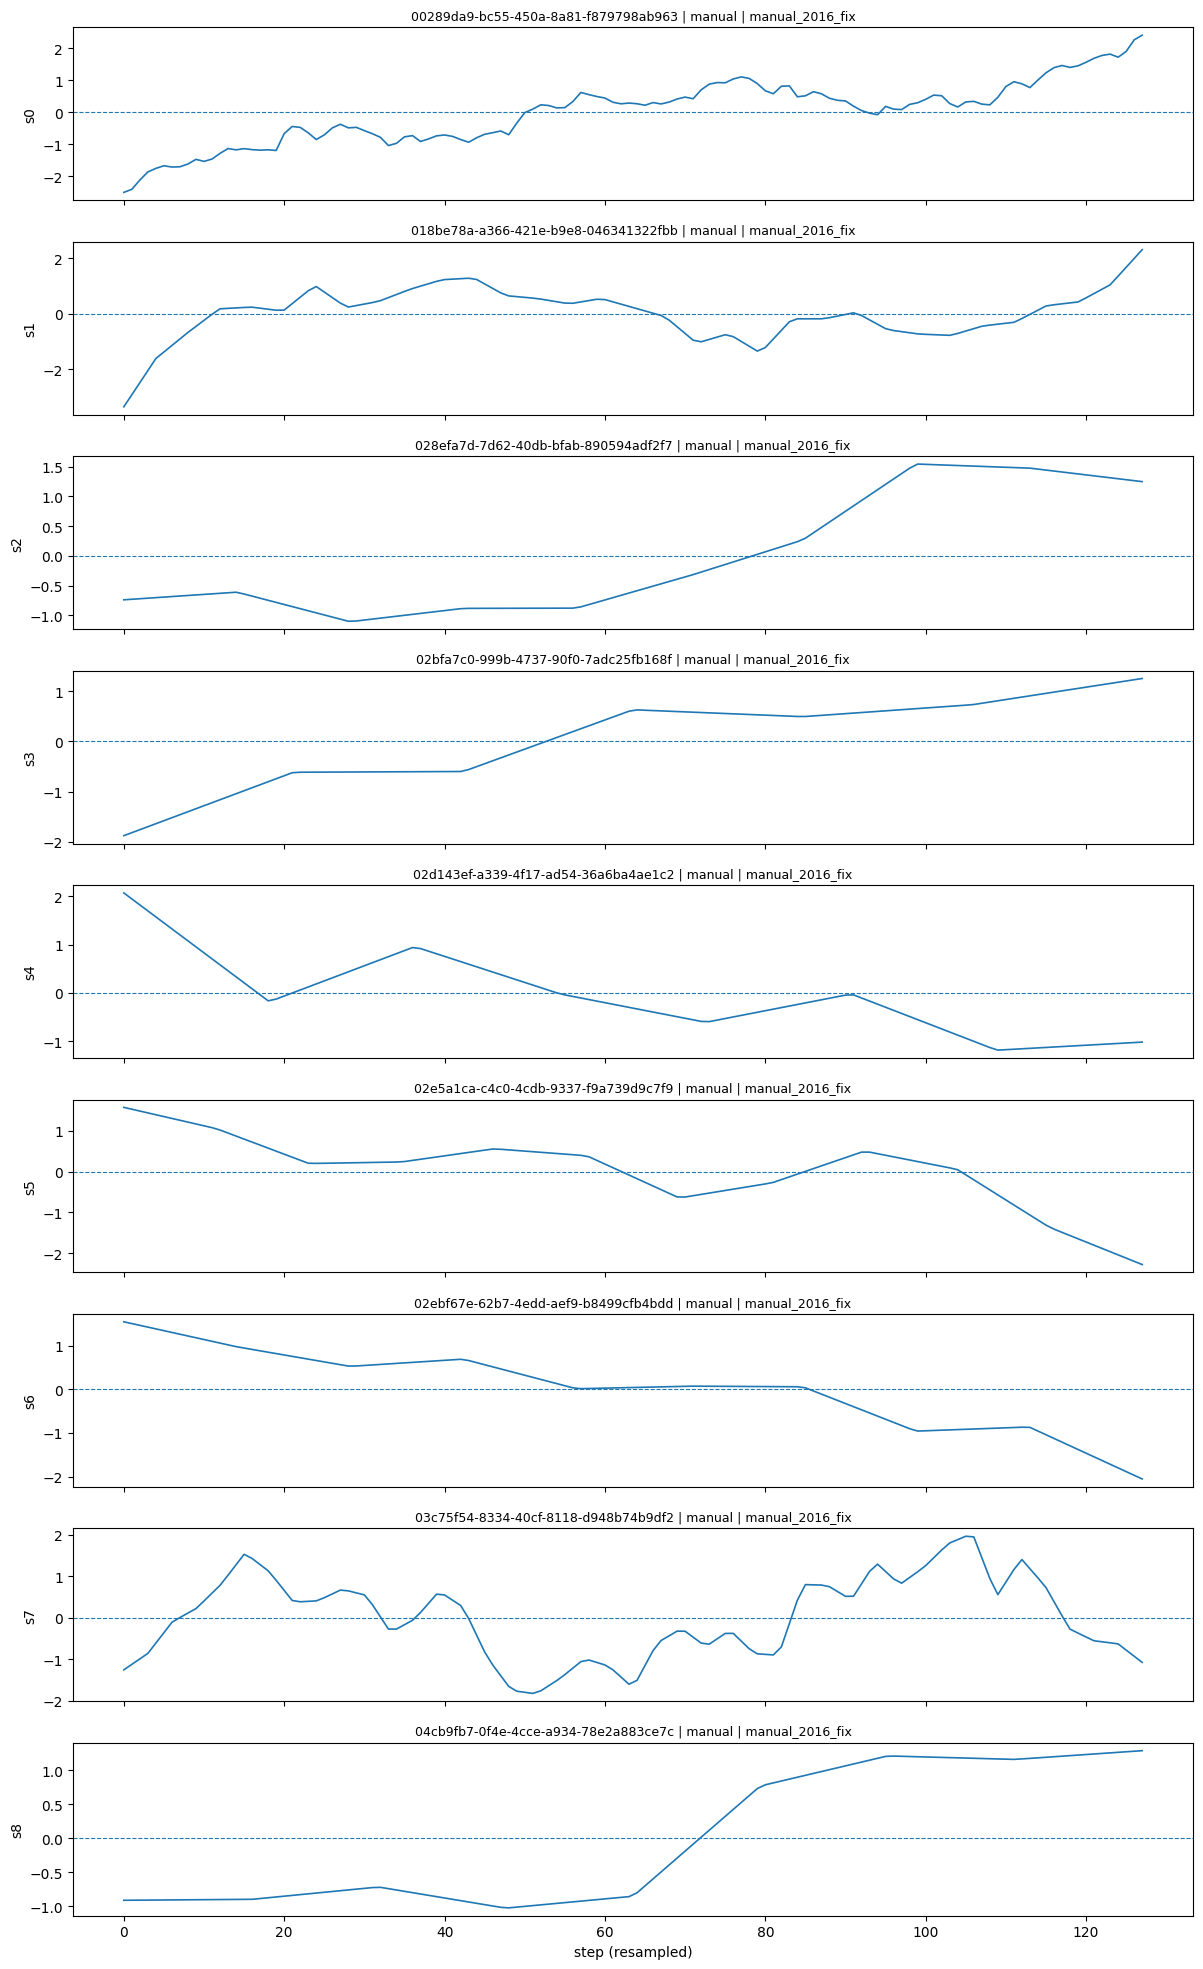

In [9]:
# =========================
# Visual rapido de secuencias normalizadas
# =========================
show_n = min(N_SHOW_EXAMPLES, len(X))
if show_n == 0:
    print('No hay secuencias para mostrar')
else:
    fig, axes = plt.subplots(show_n, 1, figsize=(12, 2.2 * show_n), sharex=True)
    if show_n == 1:
        axes = [axes]

    for i in range(show_n):
        ax = axes[i]
        ax.plot(X[i], lw=1.2)
        ax.axhline(0.0, lw=0.8, linestyle='--')
        ax.set_ylabel(f's{i}')
        ax.set_title(f"{ids[i]} | {origins[i]} | {sources[i]}", fontsize=9)

    axes[-1].set_xlabel('step (resampled)')
    plt.tight_layout()
    plt.show()


## Salidas principales

- `USDJPY_segments_extracted_catalog.parquet/csv`: metadata de cada trozo realmente extraido.
- `USDJPY_segments_extracted_long.parquet/csv`: serie OHLC por cada segmento en formato long.
- `USDJPY_segments_sequences_fixedlen.npz`: matriz `X` normalizada y reescalada (`[n_segments, TARGET_LEN]`) para autoencoder.
- `USDJPY_segments_split_temporal.parquet/csv`: split train/val/test basado en tiempo.
